ÉTAPE 2.3 : CHECKLIST QUALITÉ DES DONNÉES

1️⃣ VÉRIFICATION DES IMAGES:
----------------------------------------
✅ Images corrompues: 0
✅ Images trop petites: 0
✅ Formats bizarres: 0

👉 RÉPONSE: OUI, toutes les images sont de bonne qualité ✅

2️⃣ VÉRIFICATION DES ANNOTATIONS:
----------------------------------------
✅ Labels vides: 0
✅ Annotations mal formées: 0

👉 RÉPONSE: OUI, les calculs sont bien entourés ✅

3️⃣ QUANTITÉ DES DONNÉES:
----------------------------------------
Train: 1054 images
Valid: 123 images
Test: 123 images
Total: 1300 images

👉 RÉPONSE: OUI, assez d'images ✅

4️⃣ CONFIRMATION VISUELLE:
----------------------------------------
Voici 5 images avec leurs annotations:


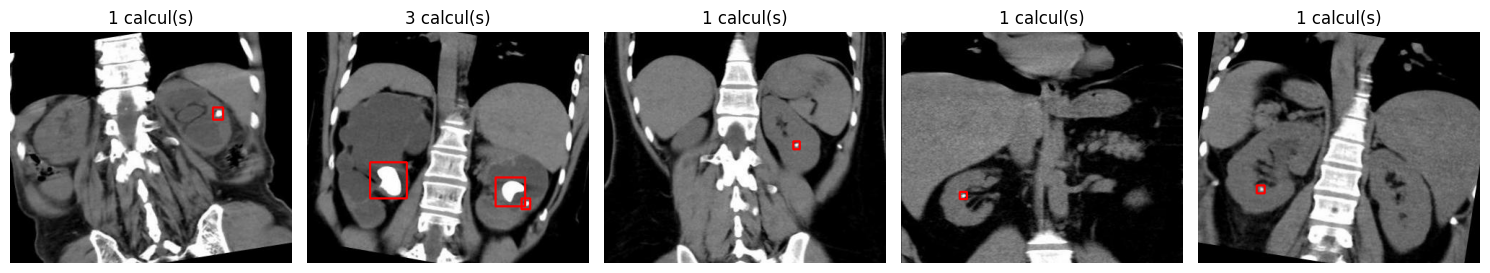


👉 REGARDEZ LES IMAGES CI-DESSUS:
   Les boîtes bleues entourent-elles correctement les calculs ?
   → Si OUI: vos données sont prêtes ✅
   → Si NON: il faut re-annoter ❌

📊 SYNTHÈSE - QUALITÉ DES DONNÉES
1. Qualité images: ✅ BONNE
2. Qualité annotations: ✅ BONNE
3. Quantité données: ✅ SUFFISANTE

🎉 CONCLUSION: VOS DONNÉES SONT PRÊTES!
→ Passez à l'ÉTAPE 3 (préparation environnement)


In [1]:
# notebooks/02_check_data_quality.ipynb
# BUT: Vérifier la qualité des données AVANT de commencer

import os
import cv2
import matplotlib.pyplot as plt
import random

print("="*60)
print("ÉTAPE 2.3 : CHECKLIST QUALITÉ DES DONNÉES")
print("="*60)

# Chemin vers vos données
train_img_dir = '../data/train/images'
train_label_dir = '../data/train/labels'

# 1. Vérifier la qualité des images
print("\n1️⃣ VÉRIFICATION DES IMAGES:")
print("-"*40)

corrupted = []
small_images = []
odd_formats = []

for img_name in os.listdir(train_img_dir)[:100]:  # Vérifier 100 images
    img_path = os.path.join(train_img_dir, img_name)
    img = cv2.imread(img_path)
    
    if img is None:
        corrupted.append(img_name)
    else:
        h, w = img.shape[:2]
        if h < 100 or w < 100:  # Image trop petite
            small_images.append(img_name)
        
        # Vérifier les formats
        if not img_name.endswith(('.jpg', '.jpeg', '.png')):
            odd_formats.append(img_name)

print(f"✅ Images corrompues: {len(corrupted)}")
print(f"✅ Images trop petites: {len(small_images)}")
print(f"✅ Formats bizarres: {len(odd_formats)}")

if len(corrupted) == 0 and len(small_images) == 0:
    print("\n👉 RÉPONSE: OUI, toutes les images sont de bonne qualité ✅")
else:
    print("\n👉 RÉPONSE: NON, il y a des problèmes ❌")

# 2. Vérifier les annotations (bounding boxes)
print("\n2️⃣ VÉRIFICATION DES ANNOTATIONS:")
print("-"*40)

bad_annotations = []
empty_labels = 0

for label_name in os.listdir(train_label_dir)[:100]:
    label_path = os.path.join(train_label_dir, label_name)
    
    with open(label_path, 'r') as f:
        lines = f.readlines()
    
    if len(lines) == 0:
        empty_labels += 1
        continue
    
    for line in lines:
        parts = line.strip().split()
        if len(parts) != 5:
            bad_annotations.append(label_name)
            break
        
        # Vérifier les coordonnées (doivent être entre 0 et 1)
        class_id, x, y, w, h = map(float, parts)
        if not (0 <= x <= 1 and 0 <= y <= 1 and 0 <= w <= 1 and 0 <= h <= 1):
            bad_annotations.append(label_name)
            break

print(f"✅ Labels vides: {empty_labels}")
print(f"✅ Annotations mal formées: {len(bad_annotations)}")

if len(bad_annotations) == 0 and empty_labels == 0:
    print("\n👉 RÉPONSE: OUI, les calculs sont bien entourés ✅")
else:
    print("\n👉 RÉPONSE: NON, il faut corriger les annotations ❌")

# 3. Vérifier la quantité de données
print("\n3️⃣ QUANTITÉ DES DONNÉES:")
print("-"*40)

n_train = len(os.listdir(train_img_dir))
n_valid = len(os.listdir('../data/valid/images'))
n_test = len(os.listdir('../data/test/images'))
total = n_train + n_valid + n_test

print(f"Train: {n_train} images")
print(f"Valid: {n_valid} images")
print(f"Test: {n_test} images")
print(f"Total: {total} images")

if total >= 500:
    print("\n👉 RÉPONSE: OUI, assez d'images ✅")
elif total >= 200:
    print("\n👉 RÉPONSE: PAS MAL, mais plus serait mieux ⚠️")
else:
    print("\n👉 RÉPONSE: NON, trop peu d'images ❌")

# 4. Visualiser POUR CONFIRMER visuellement
print("\n4️⃣ CONFIRMATION VISUELLE:")
print("-"*40)
print("Voici 5 images avec leurs annotations:")

# Prendre 5 images aléatoires
sample_images = random.sample(os.listdir(train_img_dir), min(5, len(os.listdir(train_img_dir))))

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
if len(sample_images) == 5:
    for idx, img_name in enumerate(sample_images):
        # Charger image
        img_path = os.path.join(train_img_dir, img_name)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Charger label
        label_name = img_name.replace('.jpg', '.txt').replace('.png', '.txt')
        label_path = os.path.join(train_label_dir, label_name)
        
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                annotations = f.readlines()
            
            # Dessiner boîtes
            h, w = img.shape[:2]
            for ann in annotations:
                parts = ann.strip().split()
                if len(parts) == 5:
                    _, x_c, y_c, box_w, box_h = map(float, parts)
                    x1 = int((x_c - box_w/2) * w)
                    y1 = int((y_c - box_h/2) * h)
                    x2 = int((x_c + box_w/2) * w)
                    y2 = int((y_c + box_h/2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
        
        axes[idx].imshow(img)
        axes[idx].set_title(f"{len(annotations) if os.path.exists(label_path) else 0} calcul(s)")
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print("\n👉 REGARDEZ LES IMAGES CI-DESSUS:")
    print("   Les boîtes bleues entourent-elles correctement les calculs ?")
    print("   → Si OUI: vos données sont prêtes ✅")
    print("   → Si NON: il faut re-annoter ❌")
else:
    print(f"⚠️ Pas assez d'images pour visualiser (trouvé: {len(sample_images)})")

# SYNTHÈSE FINALE
print("\n" + "="*60)
print("📊 SYNTHÈSE - QUALITÉ DES DONNÉES")
print("="*60)

qualite_images = len(corrupted) == 0 and len(small_images) == 0
qualite_annotations = len(bad_annotations) == 0
quantite_suffisante = total >= 500

print(f"1. Qualité images: {'✅ BONNE' if qualite_images else '❌ À CORRIGER'}")
print(f"2. Qualité annotations: {'✅ BONNE' if qualite_annotations else '❌ À CORRIGER'}")
print(f"3. Quantité données: {'✅ SUFFISANTE' if quantite_suffisante else '❌ INSUFFISANTE'}")

if qualite_images and qualite_annotations and quantite_suffisante:
    print("\n🎉 CONCLUSION: VOS DONNÉES SONT PRÊTES!")
    print("→ Passez à l'ÉTAPE 3 (préparation environnement)")
else:
    print("\n⚠️ CONCLUSION: CORRIGEZ D'ABORD LES PROBLÈMES CI-DESSUS")
    if not qualite_images:
        print("   → Supprimez les images corrompues")
    if not qualite_annotations:
        print("   → Vérifiez et corrigez les fichiers .txt")
    if not quantite_suffisante:
        print("   → Collectez plus d'images (objectif: 500+)")